In [8]:
import sklearn
print(sklearn.__version__)

1.9.1


In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('tips')

print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [14]:
print("Dataset Shape:", df.shape)

Dataset Shape: (244, 7)


In [15]:
print(df.columns)

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')


In [16]:
print(df.dtypes)

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


In [17]:
print(df.isnull().sum())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['sex'] = le.fit_transform(df['sex'])
df['smoker'] = le.fit_transform(df['smoker'])
df['day'] = le.fit_transform(df['day'])
df['time'] = le.fit_transform(df['time'])

print(df.head())

   total_bill   tip  sex  smoker  day  time  size
0       16.99  1.01    0       0    2     0     2
1       10.34  1.66    1       0    2     0     3
2       21.01  3.50    1       0    2     0     3
3       23.68  3.31    1       0    2     0     2
4       24.59  3.61    0       0    2     0     4


In [23]:
num_cols = ['total_bill', 'tip','size']
cat_cols = ['sex', 'smoker', 'day','time']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


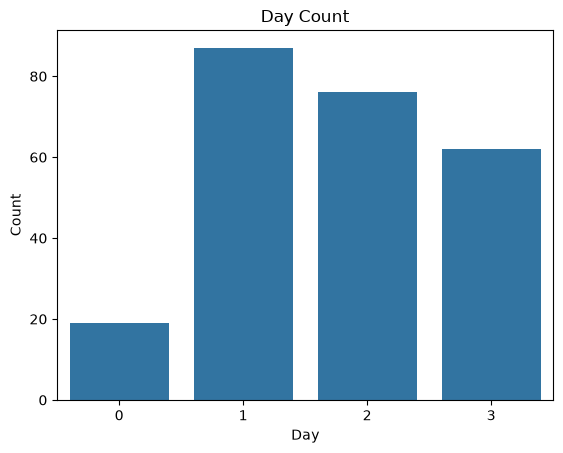

In [25]:
sns.countplot(x='day',data=df)
plt.title("Day Count")
plt.xlabel("Day")
plt.ylabel("Count")
plt.show()

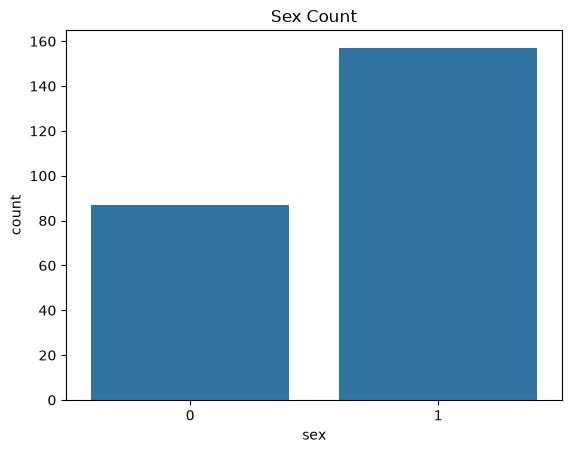

In [26]:
sns.countplot(x='sex', data=df)

plt.title("Sex Count")
plt.show()

In [29]:
print("total_bill Frequency:")
print(df['total_bill'].value_counts())

print("sex Frequency:")
print(df['sex'].value_counts())

print("size Frequency:")
print(df['size'].value_counts())

total_bill Frequency:
total_bill
13.42    3
10.34    2
21.01    2
10.33    2
17.92    2
        ..
29.03    1
27.18    1
22.67    1
17.82    1
18.78    1
Name: count, Length: 229, dtype: int64
sex Frequency:
sex
1    157
0     87
Name: count, dtype: int64
size Frequency:
size
2    156
3     38
4     37
5      5
1      4
6      4
Name: count, dtype: int64


In [30]:
print("total_bill Percentage:")
print(df['total_bill'].value_counts(normalize=True) * 100)

print("sex Percentage:")
print(df['sex'].value_counts(normalize=True) * 100)

print("size Percentage:")
print(df['size'].value_counts(normalize=True) * 100)

total_bill Percentage:
total_bill
13.42    1.229508
10.34    0.819672
21.01    0.819672
10.33    0.819672
17.92    0.819672
           ...   
29.03    0.409836
27.18    0.409836
22.67    0.409836
17.82    0.409836
18.78    0.409836
Name: proportion, Length: 229, dtype: float64
sex Percentage:
sex
1    64.344262
0    35.655738
Name: proportion, dtype: float64
size Percentage:
size
2    63.934426
3    15.573770
4    15.163934
5     2.049180
1     1.639344
6     1.639344
Name: proportion, dtype: float64


In [31]:
print("Most Common total_bill:", df['total_bill'].mode()[0])

print("Most Common size:", df['size'].mode()[0])

print("Most Common Sex:", df['sex'].mode()[0])

Most Common total_bill: 13.42
Most Common size: 2
Most Common Sex: 1


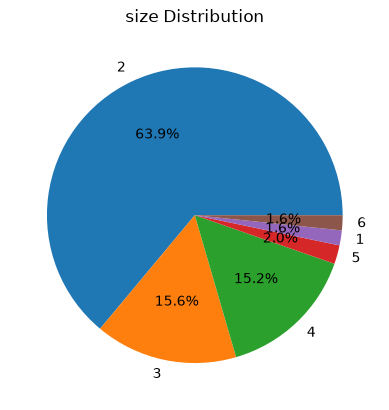

In [32]:
df['size'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("size Distribution")
plt.ylabel("")
plt.show()

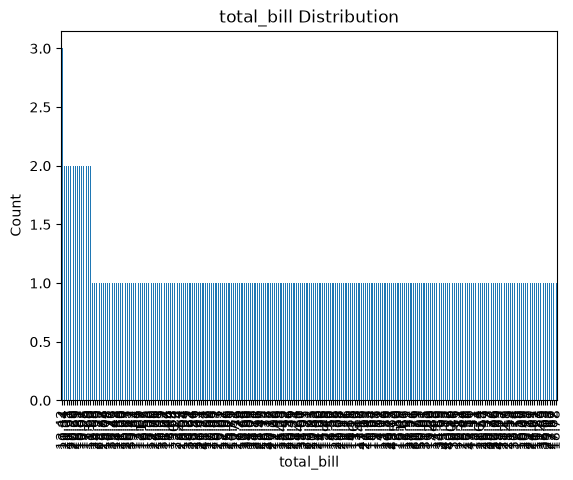

In [33]:
df['total_bill'].value_counts().plot(kind='bar')

plt.title("total_bill Distribution")
plt.xlabel("total_bill")
plt.ylabel("Count")
plt.show()

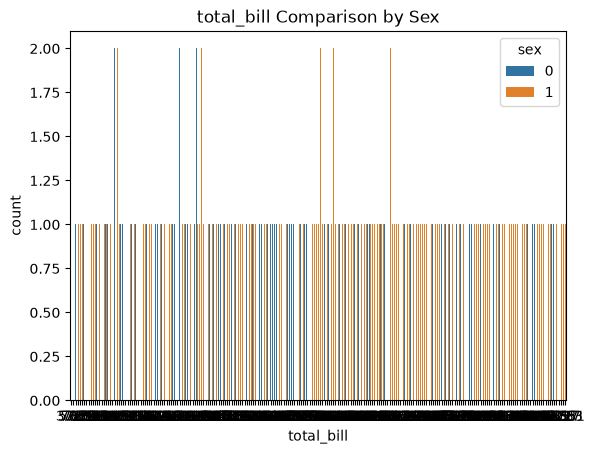

In [34]:
sns.countplot(x='total_bill', hue='sex', data=df)

plt.title("total_bill Comparison by Sex")
plt.show()